# **Data Inspection | MASSIVE-Agents**

---

**Proyek:** KP Agentic AI + LLM  
**Fokus awal:** English (`en-US`) dan Bahasa Indonesia (`id-ID`) — *full converted dataset*  

**Sumber data:** [AmazonScience/massive-agents](https://huggingface.co/datasets/AmazonScience/massive-agents), folder `massive-full-converted-all-langs-with-id`. Jumlah data dihitung langsung dari file dataset yang sudah diunduh, bukan berdasarkan jumlah yang disebutkan dalam paper.

In [1]:
from __future__ import annotations

import hashlib
import itertools
import json
import platform
import re
import sys
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

LANGUAGES = ("en-US", "id-ID")
DATASET_FOLDER = "massive-full-converted-all-langs-with-id"
SOURCE_URL = "https://huggingface.co/datasets/AmazonScience/massive-agents"

# Hanya ubah ini jika struktur folder project berbeda.
PROJECT_ROOT_OVERRIDE = None  # contoh: Path(r"D:\KP-Agentic-AI")

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Platform:", platform.platform())
print("Working directory:", Path.cwd())

Python: 3.13.12
Pandas: 3.0.6
Platform: Windows-11-10.0.26200-SP0
Working directory: d:\KP-Agentic-AI\notebooks


## **1. Menentukan Lokasi Project dan Mengecek File Dataset**

---

Jika folder tidak ditemukan secara otomatis, lokasi project bisa diatur melalui PROJECT_ROOT_OVERRIDE pada cell sebelumnya.

In [2]:
def find_project_root(override=None):
    if override is not None:
        candidates = [Path(override).expanduser()]
    else:
        current = Path.cwd().resolve()
        candidates = [current, *current.parents]

    for candidate in candidates:
        dataset_dir = candidate / "data" / "raw" / DATASET_FOLDER
        if dataset_dir.is_dir():
            return candidate.resolve()
    searched = "\n".join(str(x / "data" / "raw" / DATASET_FOLDER) for x in candidates)
    raise FileNotFoundError(
        "Folder dataset tidak ditemukan. Periksa folder project dan download.\n"
        f"Lokasi yang diperiksa:\n{searched}"
    )

PROJECT_ROOT = find_project_root(PROJECT_ROOT_OVERRIDE)
DATA_DIR = PROJECT_ROOT / "data" / "raw" / DATASET_FOLDER
OUTPUT_DIR = PROJECT_ROOT / "results" / "data_inspection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for language_code in LANGUAGES:
    for filename in ("input.jsonl", "golden.jsonl"):
        path = DATA_DIR / language_code / filename
        if not path.is_file():
            raise FileNotFoundError(f"Berkas wajib tidak ditemukan: {path}")

print("Project root :", PROJECT_ROOT)
print("Dataset path :", DATA_DIR)
print("Output folder:", OUTPUT_DIR)
print("Bahasa target:", ", ".join(LANGUAGES))

Project root : D:\KP-Agentic-AI
Dataset path : D:\KP-Agentic-AI\data\raw\massive-full-converted-all-langs-with-id
Output folder: D:\KP-Agentic-AI\results\data_inspection
Bahasa target: en-US, id-ID


## **2. Memeriksa File Dataset dan Checksum SHA-256**

---

Memeriksa ukuran dan checksum SHA-256 untuk memastikan file dataset tidak berubah, tanpa mengubah isi file.

In [3]:
def sha256_file(path: Path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

file_rows = []
for language_code in LANGUAGES:
    for filename in ("input.jsonl", "golden.jsonl"):
        file_path = DATA_DIR / language_code / filename
        file_rows.append({
            "language_code": language_code,
            "filename": filename,
            "size_mb": round(file_path.stat().st_size / 1024**2, 3),
            "sha256": sha256_file(file_path),
        })

files_df = pd.DataFrame(file_rows)
display(files_df)

,language_code,filename,size_mb,sha256
0,en-US,input.jsonl,78.074,2a43ab25bec162ae5c77e340d7afe0cdafa3dcd8972ca3...
1,en-US,golden.jsonl,0.245,aa3d369cde3d1d92c6886644d49ac797f6cfaab46d3509...
2,id-ID,input.jsonl,53.400,588a109dddb83d2da9caadfe95a9415e33728353a3cb26...
3,id-ID,golden.jsonl,0.168,f7717e3edc3bda9b7843e62cdbc23d5f3b055542e6f2a1...


## **3. Membaca JSONL dan Memeriksa Struktur Data**

---

In [4]:
issues = []
records = []
field_counts = defaultdict(Counter)
source_language_field = defaultdict(Counter)
function_catalog = defaultdict(Counter)
ground_truth_catalog = defaultdict(Counter)
file_stats = {}

ISSUE_COLUMNS = ["severity", "language_code", "source_file", "line_number", "record_id", "issue_type", "details"]


def add_issue(severity, language_code, source_file, line_number, record_id, issue_type, details):
    issues.append({
        "severity": severity,
        "language_code": language_code,
        "source_file": source_file,
        "line_number": line_number,
        "record_id": str(record_id) if record_id is not None else "",
        "issue_type": issue_type,
        "details": str(details)[:350],
    })


def parse_jsonl_line(line, language_code, source_file, line_number):
    if line is None:
        return None, "missing_line"
    if not line.strip():
        add_issue("error", language_code, source_file, line_number, None,
                  "blank_line", "Baris kosong; JSONL mengharapkan satu JSON per baris")
        return None, "blank_line"
    try:
        item = json.loads(line)
    except json.JSONDecodeError as exc:
        add_issue("error", language_code, source_file, line_number, None,
                  "invalid_json", f"Posisi karakter {exc.pos}: {exc.msg}")
        return None, "invalid_json"
    if not isinstance(item, dict):
        add_issue("error", language_code, source_file, line_number, None,
                  "not_a_json_object", f"Top-level JSON harus objek, ditemukan {type(item).__name__}")
        return None, "not_a_json_object"
    return item, "valid"


def inspect_input(item, language_code, line_number):
    record_id = item.get("id")
    if record_id is None or (isinstance(record_id, str) and not record_id.strip()):
        add_issue("error", language_code, "input.jsonl", line_number, record_id,
                  "missing_id", "ID tidak ditemukan atau kosong")
    elif isinstance(record_id, (dict, list)):
        add_issue("error", language_code, "input.jsonl", line_number, record_id,
                  "invalid_id_type", "ID berbentuk list atau dictionary")

    question = item.get("question")
    if not isinstance(question, str) or not question.strip():
        add_issue("error", language_code, "input.jsonl", line_number, record_id,
                  "missing_or_invalid_question", "Question tidak ada, kosong, atau bukan string")

    if "test_category" not in item or item.get("test_category") in (None, ""):
        add_issue("warning", language_code, "input.jsonl", line_number, record_id,
                  "missing_test_category", "Kategori pengujian kosong")

    field_counts[language_code].update(item.keys())
    source_language_field[language_code][str(item.get("language", "<missing>"))] += 1

    candidates = item.get("function")
    candidate_names = []
    candidate_schemas = {}
    if not isinstance(candidates, list):
        add_issue("error", language_code, "input.jsonl", line_number, record_id,
                  "invalid_function_catalog", "Kolom function bukan list")
    else:
        for position, entry in enumerate(candidates):
            if not isinstance(entry, dict) or not isinstance(entry.get("name"), str) or not entry["name"].strip():
                add_issue("warning", language_code, "input.jsonl", line_number, record_id,
                          "invalid_function_entry", f"Entri function indeks {position} tidak mempunyai name yang valid")
                continue
            candidate_names.append(entry["name"])
            if entry["name"] not in candidate_schemas:
                candidate_schemas[entry["name"]] = entry.get("parameters")
            function_catalog[language_code][entry["name"]] += 1
            if not isinstance(entry.get("parameters"), dict):
                add_issue("warning", language_code, "input.jsonl", line_number, record_id,
                          "invalid_parameters_schema", f"Schema parameters untuk {entry['name']} bukan dictionary")
        if len(candidate_names) != len(set(candidate_names)):
            add_issue("warning", language_code, "input.jsonl", line_number, record_id,
                      "duplicate_function_name_in_catalog", "Terdapat nama function duplikat dalam satu daftar")

    gt = item.get("gt")
    if not isinstance(gt, dict):
        add_issue("error", language_code, "input.jsonl", line_number, record_id,
                  "invalid_gt_structure", "gt bukan dictionary (nama fungsi ke argumen)")
        gt_functions = []
    else:
        gt_functions = list(gt.keys())
        if not gt_functions:
            add_issue("warning", language_code, "input.jsonl", line_number, record_id,
                      "empty_gt", "Tidak ada fungsi acuan; perlu verifikasi")
        for name, arguments in gt.items():
            ground_truth_catalog[language_code][str(name)] += 1
            if name not in candidate_names and isinstance(candidates, list):
                add_issue("error", language_code, "input.jsonl", line_number, record_id,
                          "gt_function_not_offered", f"Fungsi acuan {name!r} tidak ada di function catalog")
            if not isinstance(arguments, dict):
                add_issue("warning", language_code, "input.jsonl", line_number, record_id,
                          "gt_args_not_dict", f"Argumen untuk fungsi {name!r} bukan dictionary")
            else:
                schema = candidate_schemas.get(name)
                if isinstance(schema, dict) and isinstance(schema.get("properties"), dict):
                    unexpected = sorted(set(arguments) - set(schema["properties"]))
                    if unexpected:
                        add_issue("warning", language_code, "input.jsonl", line_number, record_id,
                                  "gt_argument_not_in_schema",
                                  f"Fungsi {name!r} memiliki argumen di luar schema: {unexpected}")

    question_text = question if isinstance(question, str) else ""
    # Hanya untuk audit duplikasi; question asli tidak ditulis ulang.
    compare_form = " ".join(question_text.split()).casefold()

    row = {
        "language_code": language_code,
        "line_number": line_number,
        "record_id": str(record_id) if record_id is not None else "",
        "question": question_text,
        "question_comparison_only": compare_form,
        "question_chars": len(question_text),
        "question_words_approx": len(question_text.split()),
        "test_category": str(item.get("test_category", "<missing>")),
        "candidate_function_count": len(candidate_names),
        "gt_function_count": len(gt_functions),
        "gt_function_names": "; ".join(map(str, gt_functions)),
        "input_golden_match": None,
    }
    return row

In [5]:
for language_code in LANGUAGES:
    input_path = DATA_DIR / language_code / "input.jsonl"
    golden_path = DATA_DIR / language_code / "golden.jsonl"
    stats = Counter()

    with input_path.open("r", encoding="utf-8-sig") as input_stream, \
         golden_path.open("r", encoding="utf-8-sig") as golden_stream:
        for line_number, (input_line, golden_line) in enumerate(
            itertools.zip_longest(input_stream, golden_stream), start=1
        ):
            if input_line is not None:
                stats["input_physical_lines"] += 1
            else:
                add_issue("error", language_code, "input.jsonl", line_number, None,
                          "missing_input_line", "golden.jsonl memiliki baris ekstra")
            if golden_line is not None:
                stats["golden_physical_lines"] += 1
            else:
                add_issue("error", language_code, "golden.jsonl", line_number, None,
                          "missing_golden_line", "input.jsonl memiliki baris ekstra")

            input_item, input_state = parse_jsonl_line(input_line, language_code, "input.jsonl", line_number)
            golden_item, golden_state = parse_jsonl_line(golden_line, language_code, "golden.jsonl", line_number)

            stats[f"input_{input_state}"] += 1
            stats[f"golden_{golden_state}"] += 1

            if golden_item is not None:
                stats["golden_valid_objects"] += 1
            if input_item is None:
                continue

            stats["input_valid_objects"] += 1
            row = inspect_input(input_item, language_code, line_number)
            gt = input_item.get("gt")

            if golden_item is not None:
                equal = gt == golden_item
                row["input_golden_match"] = equal
                if equal:
                    stats["matching_ground_truth"] += 1
                else:
                    stats["mismatching_ground_truth"] += 1
                    add_issue("error", language_code, "input.jsonl + golden.jsonl", line_number,
                              input_item.get("id"), "input_golden_mismatch",
                              "Object gt di input.jsonl berbeda dengan objek pada posisi yang sama di golden.jsonl")

            records.append(row)

    # Keduanya dihitung terpisah: validitas golden tidak bergantung pada input.
    file_stats[language_code] = dict(stats)

records_df = pd.DataFrame(records)
if records_df.empty:
    raise RuntimeError("Tidak ditemukan objek input yang valid. Periksa file raw dan laporan error.")

print("Parsing dan audit selesai. File sumber tetap tidak berubah.")
display(pd.DataFrame.from_dict(file_stats, orient="index").fillna(0).astype(int))

Parsing dan audit selesai. File sumber tetap tidak berubah.


,input_physical_lines,golden_physical_lines,input_valid,golden_valid,golden_valid_objects,input_valid_objects,matching_ground_truth
en-US,1952,1952,1952,1952,1952,1952,1952
id-ID,1335,1335,1335,1335,1335,1335,1335


### Pembacaan Data

Data pada `golden.jsonl` dicocokkan dengan `gt` pada baris yang sama di `input.jsonl`. Jika ditemukan data tidak valid atau tidak cocok, data dicatat untuk diperiksa tanpa diperbaiki otomatis.

Field `language` yang berisi `Python` bukan menunjukkan bahasa percakapan. Bahasa dataset ditentukan dari folder `en-US` (Inggris) dan `id-ID` (Indonesia).

## **4. Pemeriksaan Data Duplikat**

---

In [6]:
for language_code, lang_df in records_df.groupby("language_code", sort=False):
    id_groups = lang_df[lang_df["record_id"].ne("")].groupby("record_id", sort=False)
    for record_id, group in id_groups:
        if len(group) > 1:
            for _, item in group.iloc[1:].iterrows():
                add_issue("warning", language_code, "input.jsonl", int(item["line_number"]), record_id,
                          "duplicate_id", f"ID ini dipakai oleh {len(group)} baris pada bahasa yang sama")

    for key, issue_name, heading in [
        ("question", "duplicate_question_exact", "identik secara persis"),
        ("question_comparison_only", "duplicate_question_case_space", "sama bila case/spasi diabaikan"),
    ]:
        nonempty = lang_df[lang_df[key].ne("")]
        for value, group in nonempty.groupby(key, sort=False):
            if len(group) > 1:
                for _, item in group.iloc[1:].iterrows():
                    add_issue("info", language_code, "input.jsonl", int(item["line_number"]),
                              item["record_id"], issue_name,
                              f"Pertanyaan {heading}: {len(group)} kemunculan")

issues_df = pd.DataFrame(issues, columns=ISSUE_COLUMNS)

print("Distribusi tingkat temuan:")
if issues_df.empty:
    print("Tidak ada temuan struktural berdasarkan aturan audit yang dijalankan.")
else:
    display(pd.crosstab(issues_df["language_code"], issues_df["severity"]))
    display(issues_df.groupby(["language_code", "issue_type"]).size()
            .rename("count").reset_index().sort_values(["language_code", "count"], ascending=[True, False]))

Distribusi tingkat temuan:


severity,info,warning
language_code,,
en-US,6,1
id-ID,52,1


,language_code,issue_type,count
0,en-US,duplicate_question_case_space,3
1,en-US,duplicate_question_exact,3
2,en-US,gt_argument_not_in_schema,1
3,id-ID,duplicate_question_case_space,26
4,id-ID,duplicate_question_exact,26
5,id-ID,gt_argument_not_in_schema,1


## **5. Kualitas Data per Bahasa**

---

In [7]:
summary_rows = []
for language_code in LANGUAGES:
    lang_df = records_df[records_df["language_code"] == language_code]
    stats = file_stats[language_code]
    issue_subset = issues_df[issues_df["language_code"] == language_code] if not issues_df.empty else issues_df
    missing_questions = int(lang_df["question"].str.strip().eq("").sum())
    duplicate_id_excess = int(lang_df[lang_df["record_id"].ne("")]["record_id"].duplicated().sum())
    duplicate_question_excess = int(lang_df[lang_df["question"].ne("")]["question"].duplicated().sum())
    summary_rows.append({
        "language_code": language_code,
        "input_lines": stats.get("input_physical_lines", 0),
        "golden_lines": stats.get("golden_physical_lines", 0),
        "parsed_input_objects": stats.get("input_valid_objects", 0),
        "parsed_golden_objects": stats.get("golden_valid_objects", 0),
        "input_invalid_json": stats.get("input_invalid_json", 0),
        "golden_invalid_json": stats.get("golden_invalid_json", 0),
        "input_blank_lines": stats.get("input_blank_line", 0),
        "golden_blank_lines": stats.get("golden_blank_line", 0),
        "empty_questions": missing_questions,
        "duplicate_id_extra_rows": duplicate_id_excess,
        "duplicate_question_extra_rows": duplicate_question_excess,
        "matching_gt": stats.get("matching_ground_truth", 0),
        "mismatching_gt": stats.get("mismatching_ground_truth", 0),
        "error_findings": int(issue_subset["severity"].eq("error").sum()),
        "warning_findings": int(issue_subset["severity"].eq("warning").sum()),
        "mean_question_words": round(lang_df["question_words_approx"].mean(), 2) if not lang_df.empty else None,
        "median_question_words": round(lang_df["question_words_approx"].median(), 2) if not lang_df.empty else None,
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df.set_index("language_code").T)
print("TOTAL INPUT LINES (fokus dua bahasa):", int(summary_df["input_lines"].sum()))

ids_by_language = {
    lang: set(records_df.loc[records_df["language_code"].eq(lang) &
                                  records_df["record_id"].ne(""), "record_id"])
    for lang in LANGUAGES
}
print("ID yang muncul di kedua bahasa:", len(ids_by_language["en-US"] & ids_by_language["id-ID"]))
print("Catatan: ID yang sama antarbahasa tidak otomatis menandakan contoh kalimat ekuivalen.")

language_code,en-US,id-ID
input_lines,1952.00,1335.00
golden_lines,1952.00,1335.00
parsed_input_objects,1952.00,1335.00
parsed_golden_objects,1952.00,1335.00
input_invalid_json,0.00,0.00
golden_invalid_json,0.00,0.00
input_blank_lines,0.00,0.00
golden_blank_lines,0.00,0.00
empty_questions,0.00,0.00
duplicate_id_extra_rows,0.00,0.00


TOTAL INPUT LINES (fokus dua bahasa): 3287
ID yang muncul di kedua bahasa: 1333
Catatan: ID yang sama antarbahasa tidak otomatis menandakan contoh kalimat ekuivalen.


## **6. Contoh Data dan Struktur Fungsi**

---

In [8]:
for language_code in LANGUAGES:
    print(f"\nContoh 5 baris — {language_code}")
    preview = records_df.loc[records_df["language_code"].eq(language_code), [
        "line_number", "record_id", "question", "test_category", "gt_function_names", "input_golden_match"
    ]].head(5)
    display(preview)

    print("Nama kolom yang ditemukan:", dict(field_counts[language_code]))
    print("Nilai field 'language' pada input:", dict(source_language_field[language_code]))


Contoh 5 baris — en-US


,line_number,record_id,question,test_category,gt_function_names,input_golden_match
0,1,0,wake me up at five am this week,multiple_function,alarm.set,True
1,2,3,quiet,multiple_function,audio.volume_mute,True
2,3,8,pink is all we need,multiple_function,iot.hue_lightchange,True
3,4,14,and the darkness has fallen,multiple_function,iot.hue_lighton,True
4,5,19,olly turn the lights off in the bedroom,multiple_function,iot.hue_lightoff,True


Nama kolom yang ditemukan: {'question': 1952, 'function': 1952, 'id': 1952, 'language': 1952, 'test_category': 1952, 'gt': 1952}
Nilai field 'language' pada input: {'Python': 1952}

Contoh 5 baris — id-ID


,line_number,record_id,question,test_category,gt_function_names,input_golden_match
1952,1,0,bangunkan saya pukul lima pagi minggu ini,multiple_function,alarm.set,True
1953,2,3,diam,multiple_function,audio.volume_mute,True
1954,3,8,kami ingin merah muda,multiple_function,iot.hue_lightchange,True
1955,4,14,dan kegelapan menyelimuti,multiple_function,iot.hue_lighton,True
1956,5,19,olly matikan lampu di kamar tidur,multiple_function,iot.hue_lightoff,True


Nama kolom yang ditemukan: {'question': 1335, 'function': 1335, 'id': 1335, 'language': 1335, 'test_category': 1335, 'gt': 1335}
Nilai field 'language' pada input: {'Python': 1335}


## **7. Analisis Awal Data untuk Preprocessing**

---

Menganalisis distribusi data dan menampilkan grafik tanpa mengubah dataset asli. Panjang kalimat dihitung menggunakan `split()` sebagai perkiraan jumlah kata, bukan jumlah token yang digunakan model LLM.

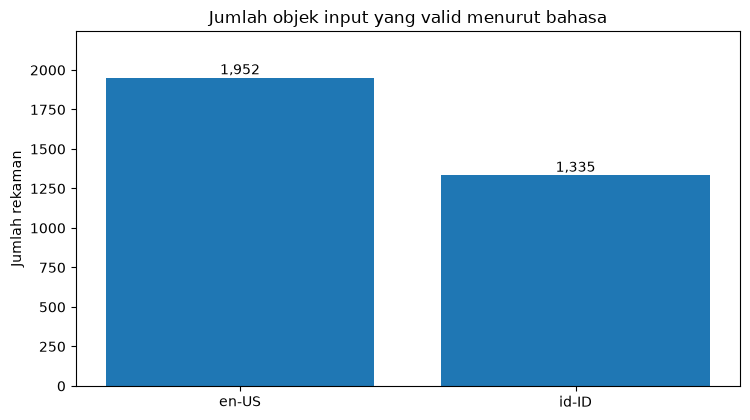

In [9]:
# Distribusi jumlah rekaman per bahasa
plt.figure(figsize=(7.6, 4.3))
counts = records_df["language_code"].value_counts().reindex(LANGUAGES, fill_value=0)
bars = plt.bar(counts.index, counts.values)
plt.title("Jumlah objek input yang valid menurut bahasa")
plt.ylabel("Jumlah rekaman")
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{count:,}",
             ha="center", va="bottom")
plt.ylim(0, max(counts.values) * 1.15 if max(counts.values) else 1)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "records_by_language.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close()

Distribusi kategori:


language_code,en-US,id-ID
test_category,,
multiple_function,1952,1335


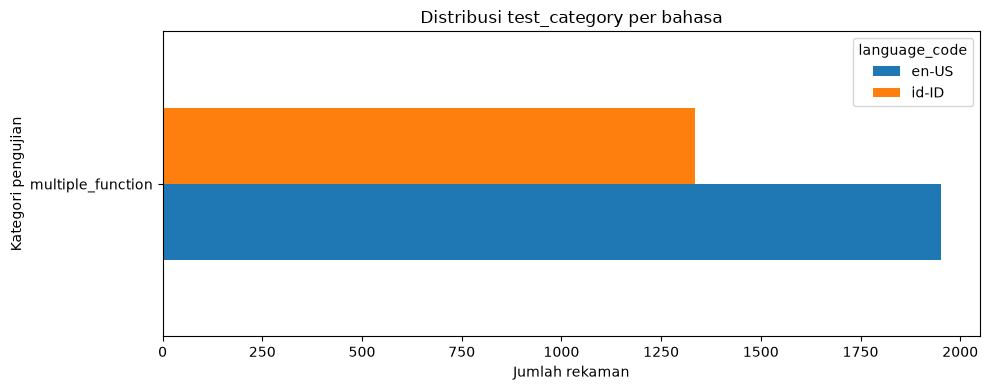

In [10]:
# Distribusi kategori pengujian: semua kategori dihitung, bukan hanya yang terbanyak.
category_df = (records_df.groupby(["language_code", "test_category"])
               .size().rename("count").reset_index())
category_pivot = (category_df.pivot(index="test_category", columns="language_code", values="count")
                  .reindex(columns=LANGUAGES).fillna(0).astype(int))
print("Distribusi kategori:")
display(category_pivot)

ax = category_pivot.plot(kind="barh", figsize=(10, max(4, len(category_pivot) * 0.45)))
ax.set_title("Distribusi test_category per bahasa")
ax.set_xlabel("Jumlah rekaman")
ax.set_ylabel("Kategori pengujian")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "category_distribution.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close()

question_chars                        question_words_approx  \
                       count   mean median min  max                 count   
language_code                                                               
en-US                   1952  34.09   32.0   5  160                  1952   
id-ID                   1335  37.10   34.0   4  153                  1335   

                                    
               mean median min max  
language_code                       
en-US          6.73    6.0   1  33  
id-ID          6.13    6.0   1  26

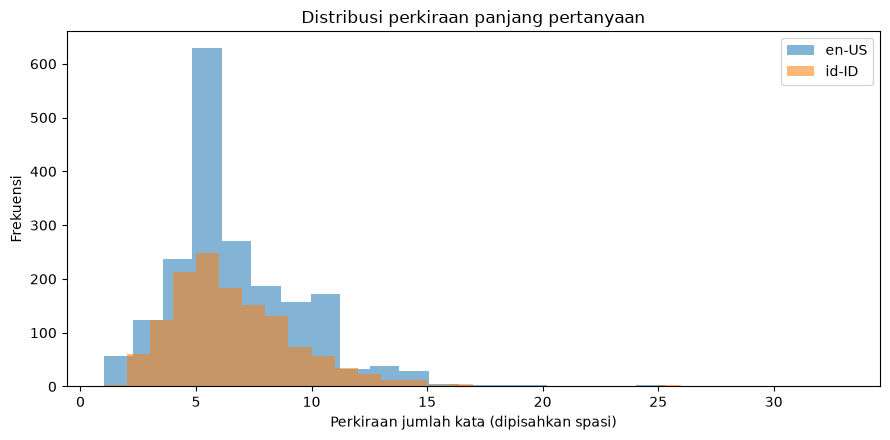

In [11]:
# Ringkasan panjang pertanyaan: tidak ada teks yang diubah.
length_stats = (records_df.groupby("language_code")[["question_chars", "question_words_approx"]]
                .agg(["count", "mean", "median", "min", "max"]).round(2))
display(length_stats)

fig, ax = plt.subplots(figsize=(9, 4.5))
for language_code in LANGUAGES:
    lengths = records_df.loc[records_df["language_code"].eq(language_code), "question_words_approx"]
    ax.hist(lengths, bins=25, alpha=0.55, label=language_code)
ax.set_title("Distribusi perkiraan panjang pertanyaan")
ax.set_xlabel("Perkiraan jumlah kata (dipisahkan spasi)")
ax.set_ylabel("Frekuensi")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "question_length_distribution.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)


en-US: fungsi paling sering muncul dalam ground truth


,function_name,gt_occurrences
0,calendar.set,138
1,play.music,121
2,qa.factoid,120
3,weather.query,106
4,calendar.query,101
5,email.query,93
6,news.query,92
7,datetime.query,61
8,calendar.remove,56
9,play.radio,55


Jumlah nama fungsi GT unik: 55
Jumlah nama fungsi yang ditawarkan unik: 55

id-ID: fungsi paling sering muncul dalam ground truth


,function_name,gt_occurrences
0,calendar.set,94
1,play.music,92
2,qa.factoid,86
3,email.query,75
4,weather.query,71
5,calendar.query,61
6,datetime.query,48
7,news.query,46
8,play.radio,43
9,calendar.remove,37


Jumlah nama fungsi GT unik: 55
Jumlah nama fungsi yang ditawarkan unik: 55


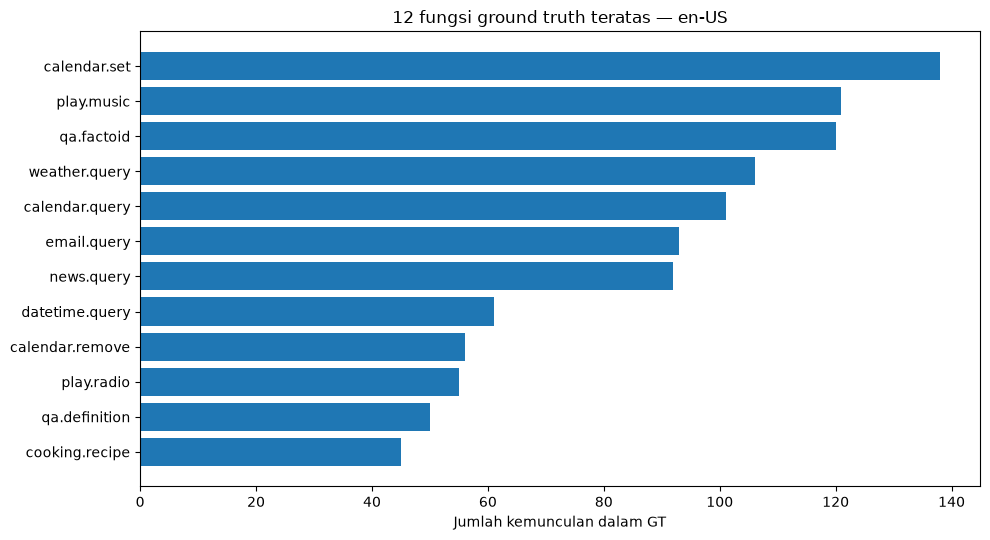

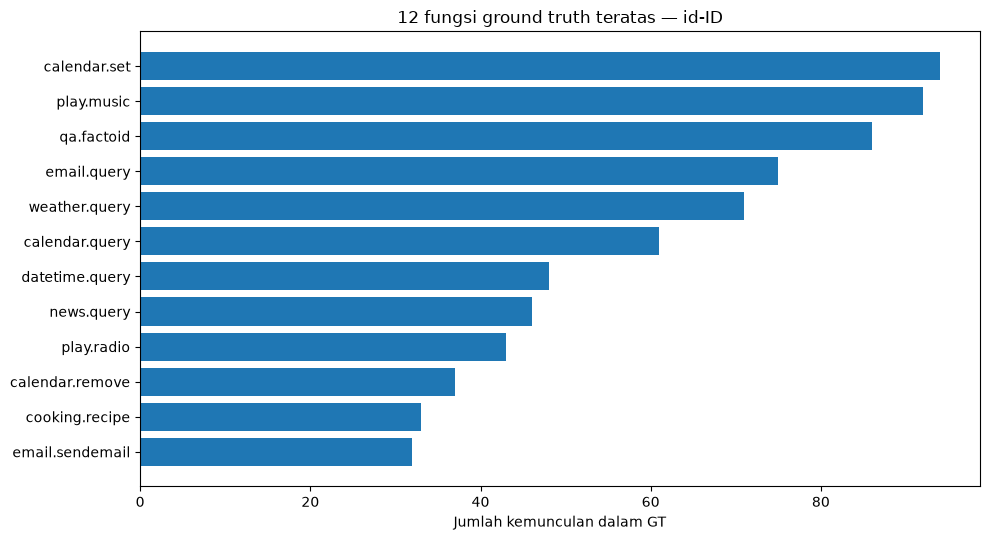

In [12]:
# Fungsi GT dan katalog fungsi tersedia diperiksa terpisah.
for language_code in LANGUAGES:
    print(f"\n{language_code}: fungsi paling sering muncul dalam ground truth")
    top = pd.DataFrame(ground_truth_catalog[language_code].most_common(15),
                       columns=["function_name", "gt_occurrences"])
    display(top)
    print("Jumlah nama fungsi GT unik:", len(ground_truth_catalog[language_code]))
    print("Jumlah nama fungsi yang ditawarkan unik:", len(function_catalog[language_code]))

for language_code in LANGUAGES:
    items = ground_truth_catalog[language_code].most_common(12)
    if not items:
        continue
    function_names, values = zip(*reversed(items))
    plt.figure(figsize=(10, 5.5))
    plt.barh(function_names, values)
    plt.title(f"12 fungsi ground truth teratas — {language_code}")
    plt.xlabel("Jumlah kemunculan dalam GT")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"gt_functions_{language_code}.png", dpi=170, bbox_inches="tight")
    plt.show()
    plt.close()

## **8. Pemeriksaan Label Variasi Bahasa**

---

Memeriksa apakah dataset memiliki label untuk membedakan bahasa formal, informal, slang, typo, dan variasi bahasa lainnya.

In [13]:
possible_register_fields = {
    "register", "style", "formality", "variant", "noise_type",
    "slang", "is_slang", "typo", "is_typo", "language_code", "locale",
}
for language_code in LANGUAGES:
    found = sorted(possible_register_fields.intersection(field_counts[language_code]))
    print(f"{language_code}: field kandidat anotasi ragam bahasa yang ditemukan: {found or 'TIDAK ADA'}")
    print(f"  test_category yang muncul: {dict(Counter(records_df.loc[records_df.language_code.eq(language_code), 'test_category']))}")
print("Catatan: ini audit nama field saja; jika ada field kandidat, nilainya tetap perlu diverifikasi manual.")

en-US: field kandidat anotasi ragam bahasa yang ditemukan: TIDAK ADA
  test_category yang muncul: {'multiple_function': 1952}
id-ID: field kandidat anotasi ragam bahasa yang ditemukan: TIDAK ADA
  test_category yang muncul: {'multiple_function': 1335}
Catatan: ini audit nama field saja; jika ada field kandidat, nilainya tetap perlu diverifikasi manual.


## **9. Menyimpan Hasil Pemeriksaan Data**

---

Seluruh hasil pemeriksaan disimpan di folder `results/data_inspection/` tanpa mengubah dataset asli.

File yang dihasilkan:
- `file_manifest.csv`: ukuran dan checksum file.
- `summary_by_language.csv`: ringkasan kualitas data per bahasa.
- `issues.csv`: daftar masalah yang ditemukan.
- `records_metadata.csv`: informasi setiap data, termasuk pertanyaan asli.
- `field_frequency.csv`: jumlah kemunculan setiap kolom.
- `gt_function_frequency.csv`: distribusi fungsi ground truth.
- `inspection_metadata.json`: informasi proses pemeriksaan.
- File `.png`: grafik hasil analisis.

File `records_metadata.csv` berisi pertanyaan asli.

In [14]:
files_df.to_csv(OUTPUT_DIR / "file_manifest.csv", index=False, encoding="utf-8-sig")
summary_df.to_csv(OUTPUT_DIR / "summary_by_language.csv", index=False, encoding="utf-8-sig")
issues_df.to_csv(OUTPUT_DIR / "issues.csv", index=False, encoding="utf-8-sig")
records_df.to_csv(OUTPUT_DIR / "records_metadata.csv", index=False, encoding="utf-8-sig")

field_rows = [
    {"language_code": lang, "field_name": field, "occurrences": count}
    for lang, counter in field_counts.items() for field, count in counter.items()
]
pd.DataFrame(field_rows, columns=["language_code", "field_name", "occurrences"]).to_csv(
    OUTPUT_DIR / "field_frequency.csv", index=False, encoding="utf-8-sig"
)

gt_function_rows = [
    {"language_code": lang, "function_name": function_name, "occurrences": count}
    for lang, counter in ground_truth_catalog.items() for function_name, count in counter.items()
]
pd.DataFrame(gt_function_rows, columns=["language_code", "function_name", "occurrences"]).to_csv(
    OUTPUT_DIR / "gt_function_frequency.csv", index=False, encoding="utf-8-sig"
)

metadata = {
    "project": "KP Agentic AI + LLM",
    "task": "data_inspection",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_source": SOURCE_URL,
    "dataset_variant": DATASET_FOLDER,
    "languages": list(LANGUAGES),
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__,
    "matplotlib_version": plt.matplotlib.__version__,
    "summary": summary_rows,
    "file_sha256": {f"{r['language_code']}/{r['filename']}": r["sha256"]
                    for r in file_rows},
}
(OUTPUT_DIR / "inspection_metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("Laporan tersimpan di:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)

Laporan tersimpan di: D:\KP-Agentic-AI\results\data_inspection
 - category_distribution.png
 - field_frequency.csv
 - file_manifest.csv
 - gt_function_frequency.csv
 - gt_functions_en-US.png
 - gt_functions_id-ID.png
 - inspection_metadata.json
 - issues.csv
 - question_length_distribution.png
 - records_by_language.png
 - records_metadata.csv
 - summary_by_language.csv


## **10. Pemeriksaan Lanjutan: Warning, Duplikasi, dan Data Antarbahasa**

---

memeriksa lebih lanjut masalah yang ditemukan pada tahap sebelumnya tanpa menghapus atau mengubah data asli.

- Pertanyaan yang sama belum tentu merupakan data yang salah. Fungsi dan argumennya perlu diperiksa terlebih dahulu.
- Warning `gt_argument_not_in_schema` menunjukkan adanya argumen ground truth yang tidak sesuai dengan skema fungsi, tetapi belum tentu salah.
- ID yang sama pada `en-US` dan `id-ID` belum tentu menunjukkan pertanyaan dengan makna yang sama.
- Label `multiple_function` pada `test_category` tidak berarti setiap data harus memanggil lebih dari satu fungsi.


In [15]:
# Ringkasan warning yang memerlukan keputusan sebelum preprocessing.
warning_df = issues_df.loc[
    issues_df['severity'].isin(['warning', 'error']),
    ISSUE_COLUMNS
].copy()
print('WARNING / ERROR YANG PERLU DITINJAU:')
if warning_df.empty:
    print('Tidak ada warning/error pada audit awal.')
else:
    display(warning_df)

# Duplikat persis: melaporkan kelompok, bukan langsung menghapus baris.
duplicate_groups_df = (
    records_df.loc[records_df['question'].str.strip().ne('')]
    .groupby(['language_code', 'question'], as_index=False)
    .agg(
        occurrences=('record_id', 'size'),
        unique_gt_function_signatures=('gt_function_names', 'nunique'),
        record_ids=('record_id', lambda s: '; '.join(map(str, s)))
    )
)
duplicate_groups_df = duplicate_groups_df.loc[
    duplicate_groups_df['occurrences'] > 1
].sort_values(['language_code','occurrences'], ascending=[True,False])

print('\nGRUP QUESTION IDENTIK DALAM MASING-MASING BAHASA:')
if duplicate_groups_df.empty:
    print('Tidak ada pertanyaan identik.')
else:
    display(duplicate_groups_df)
    print('Catatan: kesamaan nama fungsi belum membuktikan kesamaan argumen GT.')

# Pasangan berdasarkan ID; validasi one-to-one agar kegagalan ID terlihat.
needed = ['record_id','line_number','question','gt_function_names','test_category']
english = records_df.loc[records_df['language_code'].eq('en-US'), needed].rename(columns={
    'line_number':'line_en', 'question':'question_en',
    'gt_function_names':'gt_functions_en', 'test_category':'category_en'
})
indonesian = records_df.loc[records_df['language_code'].eq('id-ID'), needed].rename(columns={
    'line_number':'line_id', 'question':'question_id',
    'gt_function_names':'gt_functions_id', 'test_category':'category_id'
})

if english['record_id'].duplicated().any() or indonesian['record_id'].duplicated().any():
    print('PERINGATAN: ID duplikat dalam satu bahasa; pairing 1:1 belum dapat dipercaya.')
    paired_df = pd.DataFrame()
else:
    paired_df = english.merge(indonesian, on='record_id', how='inner', validate='one_to_one')

    def gt_function_set(value):
        return frozenset(x.strip() for x in str(value).split(';') if x.strip())

    paired_df['same_gt_function_names'] = [
        gt_function_set(e) == gt_function_set(i)
        for e, i in zip(paired_df['gt_functions_en'], paired_df['gt_functions_id'])
    ]
    paired_df['same_test_category'] = paired_df['category_en'].eq(paired_df['category_id'])
    print('\nRINGKASAN CALON PASANGAN BERDASARKAN ID:')
    print('ID yang ada pada kedua bahasa:', len(paired_df))
    print('Nama fungsi GT cocok:', int(paired_df['same_gt_function_names'].sum()))
    print('Nama fungsi GT berbeda:', int((~paired_df['same_gt_function_names']).sum()))
    print('Kategori pengujian cocok:', int(paired_df['same_test_category'].sum()))
    print('ID hanya di Inggris:', len(english) - len(paired_df))
    print('ID hanya di Indonesia:', len(indonesian) - len(paired_df))
    if (~paired_df['same_gt_function_names']).any():
        display(paired_df.loc[~paired_df['same_gt_function_names']].head(20))
    print('PERHATIAN: pairing ID dan GT function bukan validasi kualitas terjemahan.')

# Semua berkas baru hanya disimpan di folder hasil audit, tidak menyentuh data/raw.
warning_df.to_csv(OUTPUT_DIR / 'warning_details.csv', index=False, encoding='utf-8-sig')
duplicate_groups_df.to_csv(OUTPUT_DIR / 'duplicate_question_groups.csv', index=False, encoding='utf-8-sig')
paired_df.to_csv(OUTPUT_DIR / 'cross_language_pairs.csv', index=False, encoding='utf-8-sig')
print('\nLaporan lanjutan tersimpan di:', OUTPUT_DIR)


WARNING / ERROR YANG PERLU DITINJAU:


,severity,language_code,source_file,line_number,record_id,issue_type,details
0,warning,en-US,input.jsonl,1212,10061,gt_argument_not_in_schema,Fungsi 'cooking.recipe' memiliki argumen di lu...
1,warning,id-ID,input.jsonl,826,10061,gt_argument_not_in_schema,Fungsi 'cooking.recipe' memiliki argumen di lu...



GRUP QUESTION IDENTIK DALAM MASING-MASING BAHASA:


,language_code,question,occurrences,unique_gt_function_signatures,record_ids
599,en-US,i need to get a ticket via train to orlando fr...,2,1,12606; 12607
1815,en-US,what's a good joke,2,1,494; 1372
1839,en-US,what's the currency exchange rate for china,2,1,13740; 13741
2769,id-ID,matikan lampu,4,1,2711; 2774; 2775; 4347
2833,id-ID,nyalakan penyedot debu,4,1,290; 292; 1575; 2960
2126,id-ID,apakah besok akan hujan,3,1,344; 348; 6039
2815,id-ID,naikkan kecerahan lampu,3,1,962; 1756; 3883
3120,id-ID,tanggal berapa hari ini,3,1,85; 86; 2497
2004,id-ID,apa aku ada email baru,2,1,16276; 16712
2214,id-ID,bagaimana cuaca besok,2,1,2322; 4383


Catatan: kesamaan nama fungsi belum membuktikan kesamaan argumen GT.

RINGKASAN CALON PASANGAN BERDASARKAN ID:
ID yang ada pada kedua bahasa: 1333
Nama fungsi GT cocok: 1333
Nama fungsi GT berbeda: 0
Kategori pengujian cocok: 1333
ID hanya di Inggris: 619
ID hanya di Indonesia: 2
PERHATIAN: pairing ID dan GT function bukan validasi kualitas terjemahan.

Laporan lanjutan tersimpan di: D:\KP-Agentic-AI\results\data_inspection


## **11. Kesimpulan Hasil Data Inspection**

---


In [16]:
# Ringkasan hasil aktual untuk dokumentasi KP.
total = int(summary_df['parsed_input_objects'].sum())
invalid_json_count = int(summary_df['input_invalid_json'].sum() + summary_df['golden_invalid_json'].sum())
mismatch = int(summary_df['mismatching_gt'].sum())
warning_count = int(summary_df['warning_findings'].sum())
duplicate_excess = int(summary_df['duplicate_question_extra_rows'].sum())

conclusion = f"""KESIMPULAN DATA INSPECTION — MASSIVE-AGENTS

1. Dataset yang berhasil dibaca: {total:,} rekaman input dari {len(LANGUAGES)} bahasa
   (en-US: {int(summary_df.loc[summary_df.language_code.eq('en-US'),'parsed_input_objects'].iloc[0]):,};
    id-ID: {int(summary_df.loc[summary_df.language_code.eq('id-ID'),'parsed_input_objects'].iloc[0]):,}).
2. JSON invalid yang terdeteksi: {invalid_json_count}. Ketidakcocokan GT pada pasangan
   input/golden berdasarkan nomor baris: {mismatch}.
3. Ada {duplicate_excess} baris question identik tambahan dalam bahasa masing-masing.
   Ini adalah indikasi untuk review, BUKAN perintah penghapusan otomatis.
4. Ada {warning_count} warning struktur. Periksa warning_details.csv sebelum menggunakan
   semua contoh sebagai evaluasi final.
5. Label khusus formal/informal/slang/typo tidak teridentifikasi pada field yang diperiksa.
   Belum dapat disimpulkan bahwa data teks tidak memuat ragam-ragam tersebut.
6. ID bersama antardua bahasa: {len(paired_df) if not paired_df.empty else 'belum dapat dihitung'}.
   Pairing ID dan kecocokan nama fungsi GT tidak menjamin ekuivalensi terjemahan.
7. STATUS: siap melanjutkan EDA, tetapi keputusan cleaning, subset, augmentasi slang/typo,
   pembagian train/dev/test, serta pemilihan sampel evaluasi BELUM final.
"""
print(conclusion)
(OUTPUT_DIR / 'inspection_conclusion.txt').write_text(conclusion, encoding='utf-8')


KESIMPULAN DATA INSPECTION — MASSIVE-AGENTS

1. Dataset yang berhasil dibaca: 3,287 rekaman input dari 2 bahasa
   (en-US: 1,952;
    id-ID: 1,335).
2. JSON invalid yang terdeteksi: 0. Ketidakcocokan GT pada pasangan
   input/golden berdasarkan nomor baris: 0.
3. Ada 29 baris question identik tambahan dalam bahasa masing-masing.
   Ini adalah indikasi untuk review, BUKAN perintah penghapusan otomatis.
4. Ada 2 warning struktur. Periksa warning_details.csv sebelum menggunakan
   semua contoh sebagai evaluasi final.
5. Label khusus formal/informal/slang/typo tidak teridentifikasi pada field yang diperiksa.
   Belum dapat disimpulkan bahwa data teks tidak memuat ragam-ragam tersebut.
6. ID bersama antardua bahasa: 1333.
   Pairing ID dan kecocokan nama fungsi GT tidak menjamin ekuivalensi terjemahan.
7. STATUS: siap melanjutkan EDA, tetapi keputusan cleaning, subset, augmentasi slang/typo,
   pembagian train/dev/test, serta pemilihan sampel evaluasi BELUM final.



974

## **12. Insight Data Inspection**

---

| Temuan | Insight |
|---|---|
| Terdapat data dengan format JSON atau ground truth yang tidak sesuai | Data perlu diperiksa lebih lanjut untuk memastikan struktur dan anotasinya benar. |
| Ditemukan ID atau pertanyaan yang berulang | Data duplikat belum tentu salah karena bisa memiliki fungsi, argumen, atau konteks yang berbeda. |
| Terdapat fungsi ground truth yang tidak sesuai dengan daftar fungsi | Kesesuaian fungsi dan argumen perlu diperiksa agar hasil evaluasi model akurat. |
| Jumlah data Bahasa Inggris dan Indonesia berbeda | Perbedaan jumlah data perlu diperhatikan agar perbandingan performa kedua bahasa tetap adil. |
| Belum tersedia label formal, informal, slang, dan typo | Dataset belum dapat digunakan untuk membandingkan setiap variasi bahasa secara langsung tanpa pemeriksaan atau anotasi tambahan. |
| Variasi slang dan typo mungkin sudah terdapat dalam data asli | Perlu analisis lebih lanjut untuk mengetahui variasi bahasa yang benar-benar tersedia sebelum menambahkan data baru. |
